# Team 10 - FirstByte2026 Data Analysis
## Goals:
- Explain how NorthByte's revenue and costs changed between FY2024-25 and FY2025-26, when did results start to decline, and which changes explain most of the drop
- Analyze how financial performance differs across NorthByte's network (+ whether some parts of the business carry others)
- How much rising fuel and crew costs, refunds, and rewards program contribute to the decline (+ what factors matter most?)
- What role ancillary revenue, refunds, and connected passengers play in how NorthByte earns its money
- How NorthByte's gate lease costs changed from the 2024-2025 lease year to the 2025-2026 lease year.
- Based on those trends, what would you expect NorthByte to pay for its gates in 2026-2027

## EDA

In [1]:
import pandas as pd

transactions_file = pd.read_csv("../data/transactions.xlsx - Transactions.csv")
costs_file = pd.read_csv("../data/costs.xlsx - Costs.csv")
gates_file = pd.read_csv("../data/gates.xlsx - Gates.csv")

datasets = {
    "Transactions": transactions_file,
    "Costs": costs_file,
    "Gates": gates_file
}

# summary of datasets
for name, df in datasets.items():
    print(name)
    print("Shape:", df.shape)
    print("\nColumns and data types:")
    print(df.dtypes)
    print("\nFirst 5 rows:")
    display(df.head())
    print("\nSummary statistics:")
    display(df.describe(include="all").T)


Transactions
Shape: (559985, 9)

Columns and data types:
Transaction_ID      str
Booking_ID          str
Transaction_Date    str
Route_ID            str
Transaction_Type    str
Membership_Tier     str
Booking_Channel     str
Payment_Method      str
Amount              str
dtype: object

First 5 rows:


,Transaction_ID,Booking_ID,Transaction_Date,Route_ID,Transaction_Type,Membership_Tier,Booking_Channel,Payment_Method,Amount
0,TX1525667,BK396819,2026-07-23 18:18,YYZYHZ,Ticket,Non-Member,Direct Web,Credit Card,$954.80
1,TX1420893,BK245942,2026-03-14 05:23,yvr-yeg,Ticket,Blue,Corporate Portal,Credit Card,$971.17
2,TX1313706,BK274024,2025-10-29 11:54,yvryeg,Food & Onboard,Non-Member,Online Travel Agency,Credit Card,$9.87
3,TX1169582,BK374084,2025-04-30 02:50,YYT-YHZ,Ticket,Silver,Direct Web,Credit Card,$744.61
4,TX1378465,BK319834,01/20/2026 04:02,YYZYYC,Ticket,Blue,Direct Web,Credit Card,"$1,380.38"



Summary statistics:


,count,unique,top,freq
Transaction_ID,559985,558129,TX1290922,2
Booking_ID,559985,353002,BK383629,7
Transaction_Date,559985,402758,2025-12-03 03:45,8
Route_ID,559985,216,YYC-YVR,10560
Transaction_Type,559985,72,Ticket,300167
Membership_Tier,555880,22,Non-Member,245392
Booking_Channel,559985,28,Direct Web,180024
Payment_Method,555529,48,Credit Card,309684
Amount,559985,161206,$75.00,10469


Costs
Shape: (115204, 7)

Columns and data types:
Cost_ID          str
Cost_Date        str
Cost_Type        str
Route_ID         str
From             str
To               str
Amount       float64
dtype: object

First 5 rows:


,Cost_ID,Cost_Date,Cost_Type,Route_ID,From,To,Amount
0,CO000001,2024-09-01 06:30,Crew,YVR-YLW,Vancouver,Kelowna,1388.53
1,CO000002,2024-09-01 06:30,Food,yvr-ylw,Vancouver,Kelowna,170.52
2,CO000003,2024-09-01 06:30,Fuel,YVR-YLW,Vancouver,Kelowna,1401.75
3,CO000004,2024-09-01 06:30,Maintenance,yvrylw,Vancouver,Kelowna,1657.45
4,CO000005,2024-09-01 06:35,Crew,YLW-YYC,Kelowna,Calgary,1673.28


... (2 outputs left out)

Gates
Shape: (112, 5)

Columns and data types:
City                str
Gate_Number         str
Route_ID            str
Year                str
Annual_Gate_Cost    str
dtype: object

First 5 rows:


,City,Gate_Number,Route_ID,Year,Annual_Gate_Cost
0,Abbotsford,G1,yxx-yyc,2024-2025,"166,800"
1,Calgary,B1,YYCYVR,2024-2025,"373,200"
2,Calgary,B1,yycyyz,2024-2025,"373,200"
3,Calgary,B1,YYCYEG,2024-2025,"373,200"
4,Calgary,B2,yyc-ywg,2024-2025,"351,900"



Summary statistics:


,count,unique,top,freq
City,112,20,Calgary,16
Gate_Number,112,15,A1,22
Route_ID,108,54,yxx-yyc,2
Year,112,2,2024-2025,56
Annual_Gate_Cost,112,56,"455,100",6


In [2]:
for name, df in datasets.items():
    print(f"\n{'*' * 50}")
    print(name)

    print("\nMissing values:")
    print(df.isna().sum().sort_values(ascending=False))

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nUnique values per column:")
    print(df.nunique(dropna = False).sort_values())


**************************************************
Transactions

Missing values:
Payment_Method      4456
Membership_Tier     4105
Transaction_ID         0
Booking_ID             0
Transaction_Date       0
Transaction_Type       0
Route_ID               0
Booking_Channel        0
Amount                 0
dtype: int64

Duplicate rows: 919

Unique values per column:
Membership_Tier         23
Booking_Channel         28
Payment_Method          49
Transaction_Type        72
Route_ID               216
Amount              161206
Booking_ID          353002
Transaction_Date    402758
Transaction_ID      558129
dtype: int64

**************************************************
Costs

Missing values:
Cost_ID      0
Cost_Date    0
Cost_Type    0
Route_ID     0
From         0
To           0
Amount       0
dtype: int64

Duplicate rows: 0

Unique values per column:
Cost_Type         4
From             20
To               20
Route_ID        216
Cost_Date     17241
Amount       100616
Cost_ID      1152

In [3]:
# Exploring Duplicated rows
print("Exact duplicate rows:", transactions_file.duplicated().sum())

print("\nDuplicate Transaction_ID rows:")
print(transactions_file["Transaction_ID"].duplicated().sum())

print("\nExamples of exact duplicate rows:")
display(transactions_file[transactions_file.duplicated(keep=False)].sort_values("Transaction_ID").head(20))

# Exploring categorical values
categorical_cols = [
    "Transaction_Type",
    "Booking_Channel",
    "Payment_Method",
    "Membership_Tier"
]

for col in categorical_cols:
    print(f"\n{'*' * 40}\n{col}")
    print(
        transactions_file[col].value_counts(dropna=False).to_string()
    )

# Check for whitespace/capitalization differences
for col in categorical_cols + ["Route_ID"]:
    values = transactions_file[col].dropna().astype(str)

    print(f"\n{col}")
    print("Values with leading/trailing whitespace:",
          (values != values.str.strip()).sum())
    print("Unique original values:", values.nunique())
    print("Unique after stripping whitespace:",
          values.str.strip().nunique())
    print("Unique after stripping + lowercase",
          values.str.strip().str.lower().nunique())
    
# Exploring missing transaction information 
for col in ["Membership_Tier", "Payment_Method"]:
    print(f"\nMissing {col} by transaction type:")
    display(
        transactions_file.assign(Is_Missing=transactions_file[col].isna())
        .groupby("Transaction_Type", dropna=False)["Is_Missing"].agg(["sum", "count", "mean"]).sort_values("sum", ascending=False)
    )

# checking amounts and dates
transactions_file["Amount"] = pd.to_numeric(
    transactions_file["Amount"]
        .astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip(),
    errors="coerce"
) # ensure "Amount" column is numeric

print("\nTransaction amount summary:")
display(transactions_file["Amount"].describe())

print("\nZero amounts:", (transactions_file["Amount"] == 0).sum())

print("\nNegative amounts:", (transactions_file["Amount"] < 0).sum())

print("Invalid transaction dates:", transactions_file["Transaction_Date"].isna().sum())

print("Transaction date range:", transactions_file["Transaction_Date"].min(), "to", transactions_file["Transaction_Date"].max())

# Check route consistency between the datasets
transaction_routes = set(transactions_file["Route_ID"].dropna().astype(str).str.strip())
cost_routes = set(costs_file["Route_ID"].dropna().astype(str).str.strip())
gates_routes = set(gates_file["Route_ID"].dropna().astype(str).str.strip())

print("\nRoute IDs:")
print("Transactions:", len(transaction_routes))
print("Costs:", len(cost_routes))
print("Gates:", len(gates_routes))

print("\nTransaction routes missing from costs:",
      len(transaction_routes - cost_routes))
print("Cost routes missing from transactions:",
      len(cost_routes - transaction_routes))
print("Transaction routes missing from gates:",
      len(transaction_routes - gates_routes))

Exact duplicate rows: 919

Duplicate Transaction_ID rows:
1856

Examples of exact duplicate rows:


,Transaction_ID,Booking_ID,Transaction_Date,Route_ID,Transaction_Type,Membership_Tier,Booking_Channel,Payment_Method,Amount
18883,TX1000200,BK247854,09/01/2024 08:06,YHZYUL,Ticket,Non-Member,Corporate Portal,Points + Cash,"$1,019.00"
107840,TX1000200,BK247854,09/01/2024 08:06,YHZYUL,Ticket,Non-Member,Corporate Portal,Points + Cash,"$1,019.00"
243826,TX1001267,BK146372,2024-09-03 10:44,yhz-yyz,Ticket,Non-Member,Website,Travel Voucher,"$1,256.40"
442476,TX1001267,BK146372,2024-09-03 10:44,yhz-yyz,Ticket,Non-Member,Website,Travel Voucher,"$1,256.40"
4546,TX1003061,BK194363,2024-09-06 18:31,ylw-yvr,Ticket,Non-Member,Mobile App,Credit Card,$490.43
56702,TX1003061,BK194363,2024-09-06 18:31,ylw-yvr,Ticket,Non-Member,Mobile App,Credit Card,$490.43
528628,TX1004569,BK218458,2024-09-09 12:44,YHZ-YYZ,Ticket,Gold,Mobile App,Debit,"$1,201.99"
451738,TX1004569,BK218458,2024-09-09 12:44,YHZ-YYZ,Ticket,Gold,Mobile App,Debit,"$1,201.99"
478650,TX1004971,BK331807,2024-09-10 08:55,yycyqr,Extra Baggage,Non-Member,Mobile App,Credit Card,$38.72
261297,TX1004971,BK331807,2024-09-10 08:55,yycyqr,Extra Baggage,Non-Member,Mobile App,Credit Card,$38.72



****************************************
Transaction_Type
Transaction_Type
Ticket              300167
Extra Baggage        71605
Food & Onboard       43645
Seat Upgrade         19916
TICKET               13462
ticket               13185
 Ticket              12688
Ticket               12241
 Ticket              12234
Change Fee           11632
Refund               10905
extra baggage         3168
EXTRA BAGGAGE         3093
 Extra Baggage        3037
 Extra Baggage        2963
Extra Baggage         2729
 Food & Onboard       1961
food & onboard        1915
 Food & Onboard       1717
FOOD & ONBOARD        1709
Food & Onboard        1683
 Seat Upgrade          889
seat upgrade           869
SEAT UPGRADE           818
Seat Upgrade           805
 Seat Upgrade          698
 ticket                593
TICKET                 584
REFUND                 572
 TICKET                568
 ticket                557
 Refund                554
 Change Fee            553
change fee             549
 TICKE

,sum,count,mean
Transaction_Type,,,
Ticket,2257,300167,0.007519
Extra Baggage,540,71605,0.007541
Food & Onboard,350,43645,0.008019
Seat Upgrade,128,19916,0.006427
TICKET,108,13462,0.008023
...,...,...,...
TICKET,0,584,0.000000
extra baggage,0,149,0.000000
food & onboard,0,66,0.000000



Missing Payment_Method by transaction type:


,sum,count,mean
Transaction_Type,,,
Ticket,2423,300167,0.008072
Extra Baggage,609,71605,0.008505
Food & Onboard,273,43645,0.006255
Ticket,155,12241,0.012662
Seat Upgrade,116,19916,0.005824
...,...,...,...
TICKET,0,584,0.000000
refund,0,13,0.000000
food & onboard,0,66,0.000000



Transaction amount summary:


count    559985.000000
mean        664.053185
std         709.754388
min       -2946.180000
25%          52.430000
50%         621.980000
75%         930.890000
max        2962.910000
Name: Amount, dtype: float64


Zero amounts: 0

Negative amounts: 13564
Invalid transaction dates: 0
Transaction date range: 01/01/2025 01:18 to 31/12/2025 21:55

Route IDs:
Transactions: 216
Costs: 216
Gates: 54

Transaction routes missing from costs: 0
Cost routes missing from transactions: 0
Transaction routes missing from gates: 162


## Transaction Data Quality + Deduplication
Before conducting any analysis, the transactions dataset must be checked for duplicate records and inconsistent dates, as these issues could inflate revenue or assign revenue to the wrong month.

Our investigation identified:
- 919 exact duplicate rows
- Repeated Transaction_ID values, of whihc some became identical after standardizing text fields and route identifiers
- 29 Transaction_IDs whose records match on all details but have different dates. This is due to date formatting inconsistencies, such as DD/MM/YYYY versis MM/DD/YYYY. 

Since Transaction_ID is supposed to be unique and identify an individual transaction, we should not retain multiple copies of the same transaction because we could potentially be counting revenue twice. We need to further investigate because the date will determine the month and fiscal year in which revenue is reported.

The cleaning approach we will use is to preserve the original data, standardize the date representations, investigate the repeated IDs, remove the exact duplicate records, and validate the dataset that results. Any ambiguity and assumptions will be documented.

In [4]:
# Preserve the original date strings for investigation
date_check = transactions_file.copy()

date_check["Transaction_Date_Raw"] = (
    date_check["Transaction_Date"].astype("string").str.strip()
)

# Identify year-first date strings
date_check["is_year_first"] = (
    date_check["Transaction_Date_Raw"]
    .str.match(r"^\d{4}[-/]\d{1,2}[-/]\d{1,2}", na=False)
)

# Find transaction IDs appearing more than once
repeated_ids = date_check[
    date_check.duplicated("Transaction_ID", keep=False)
]

# Display repeated IDs where raw date strings differ
different_dates = (
    repeated_ids.groupby("Transaction_ID")["Transaction_Date_Raw"]
    .nunique()
)

different_date_ids = different_dates[different_dates > 1].index

date_pairs = repeated_ids[
    repeated_ids["Transaction_ID"].isin(different_date_ids)
].sort_values("Transaction_ID")

display(
    date_pairs[
        [
            "Transaction_ID",
            "Transaction_Date_Raw",
            "is_year_first",
            "Amount"
        ]
    ]
)

,Transaction_ID,Transaction_Date_Raw,is_year_first,Amount
835,TX1003332,2024-09-07 07:53,True,494.94
495811,TX1003332,09/07/2024 07:53,False,494.94
310800,TX1003829,09/08/2024 06:38,False,659.06
421004,TX1003829,2024-09-08 06:38,True,659.06
133550,TX1007879,2024-09-15 19:12,True,607.37
...,...,...,...,...
131331,TX1552386,08/25/2026 15:02,False,796.00
119815,TX1555418,29/08/2026 13:29,False,665.29
554066,TX1555418,08/29/2026 13:29,False,665.29
245389,TX9900824,2025-06-25 15:37,True,52.72


In [5]:
date_check = transactions_file.copy()

date_check["Transaction_Date_Raw"] = (
    date_check["Transaction_Date"].astype("string").str.strip()
)

raw = date_check["Transaction_Date_Raw"]

date_check["is_year_first"] = raw.str.match(
    r"^\d{4}[-/]\d{1,2}[-/]\d{1,2}",
    na=False
)

# Parse year-first dates unambiguously
date_check["parsed_date"] = pd.NaT

mask_iso = date_check["is_year_first"]

date_check.loc[mask_iso, "parsed_date"] = pd.to_datetime(
    raw[mask_iso],
    format="mixed",
    errors="coerce"
)

# Parse slash dates under both possible conventions
slash_mask = ~mask_iso

date_check["slash_month_first"] = pd.NaT
date_check["slash_day_first"] = pd.NaT

date_check.loc[slash_mask, "slash_month_first"] = pd.to_datetime(
    raw[slash_mask],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

date_check.loc[slash_mask, "slash_day_first"] = pd.to_datetime(
    raw[slash_mask],
    format="%d/%m/%Y %H:%M",
    errors="coerce"
)

# Compare each slash date against the ISO date for the same transaction ID
iso_dates = (
    date_check.loc[mask_iso]
    .groupby("Transaction_ID")["parsed_date"]
    .first()
)

date_check["matching_iso_date"] = (
    date_check["Transaction_ID"].map(iso_dates)
)

date_check["matches_month_first"] = (
    date_check["slash_month_first"]
    == date_check["matching_iso_date"]
)

date_check["matches_day_first"] = (
    date_check["slash_day_first"]
    == date_check["matching_iso_date"]
)

slash_pairs = date_check[
    slash_mask & date_check["matching_iso_date"].notna()
].copy()

display(
    slash_pairs[
        [
            "Transaction_ID",
            "Transaction_Date_Raw",
            "matching_iso_date",
            "slash_month_first",
            "slash_day_first",
            "matches_month_first",
            "matches_day_first"
        ]
    ].head(30)
)

print("Slash records with matching ISO records:", len(slash_pairs))
print("Matching month-first:", slash_pairs["matches_month_first"].sum())
print("Matching day-first:", slash_pairs["matches_day_first"].sum())

,Transaction_ID,Transaction_Date_Raw,matching_iso_date,slash_month_first,slash_day_first,matches_month_first,matches_day_first
5144,TX1324632,12/11/2025 11:24,2025-11-12 11:24:00,2025-12-11 11:24:00,2025-11-12 11:24:00,False,True
11917,TX1323104,10/11/2025 14:34,2025-11-10 14:34:00,2025-10-11 14:34:00,2025-11-10 14:34:00,False,True
14190,TX1342745,05/12/2025 12:59,2025-12-05 12:59:00,2025-05-12 12:59:00,2025-12-05 12:59:00,False,True
29761,TX1178183,05/11/2025 12:42,2025-05-11 12:42:00,2025-05-11 12:42:00,2025-11-05 12:42:00,True,False
31491,TX1440634,08/04/2026 10:23,2026-04-08 10:23:00,2026-08-04 10:23:00,2026-04-08 10:23:00,False,True
35368,TX1158046,14/04/2025 04:29,2025-04-14 04:29:00,NaT,2025-04-14 04:29:00,False,True
54178,TX1262364,22/08/2025 21:27,2025-08-22 21:27:00,NaT,2025-08-22 21:27:00,False,True
57388,TX1481272,06/01/2026 10:09,2026-06-01 10:09:00,2026-06-01 10:09:00,2026-01-06 10:09:00,True,False
58572,TX1063098,06/12/2024 19:18,2024-12-06 19:18:00,2024-06-12 19:18:00,2024-12-06 19:18:00,False,True
60052,TX1510735,07/05/2026 22:14,2026-07-05 22:14:00,2026-07-05 22:14:00,2026-05-07 22:14:00,True,False


Slash records with matching ISO records: 125
Matching month-first: 70
Matching day-first: 60


In [6]:
# Classify each slash-formatted record by the evidence available
month_only = (
    slash_pairs["matches_month_first"]
    & ~slash_pairs["matches_day_first"]
)

day_only = (
    slash_pairs["matches_day_first"]
    & ~slash_pairs["matches_month_first"]
)

both_match = (
    slash_pairs["matches_month_first"]
    & slash_pairs["matches_day_first"]
)

neither_match = (
    ~slash_pairs["matches_month_first"]
    & ~slash_pairs["matches_day_first"]
)

print("Slash records with matching ISO records:", len(slash_pairs))
print("Month-first only:", month_only.sum())
print("Day-first only:", day_only.sum())
print("Both interpretations match:", both_match.sum())
print("Neither interpretation matches:", neither_match.sum())

# Inspect dates where neither interpretation matches
display(
    slash_pairs.loc[
        neither_match,
        [
            "Transaction_ID",
            "Transaction_Date_Raw",
            "matching_iso_date",
            "slash_month_first",
            "slash_day_first"
        ]
    ]
)

Slash records with matching ISO records: 125
Month-first only: 65
Day-first only: 55
Both interpretations match: 5
Neither interpretation matches: 0


,Transaction_ID,Transaction_Date_Raw,matching_iso_date,slash_month_first,slash_day_first


## Dates and handling ambiguity
Our date format investigation identified both MM/DD/YYYY and DD/MM/YYYY conventions in the dataset. Applying one single convention across all data could misclassify transactions. I will use these rules:

1. Year-first dates: Parse ISO-style dates directly
2. Slash dates with a matching ISO record: Use the matching ISO date, after confirmation that the other transactions details of the example are the same
3. Unambiguous slash dates: For example, if the first date component is greater than 12, it should be interpreted as the day, if the second is greater than 12, interpret as the day. If both are equal, then either convention is the same date.
4. Ambiguous slash dates: If both first or second component is 12 or less and different, and there is no matching ISO date, then flag that date.

In [7]:
# Start with a separate column for the cleaned dates.
date_check["Transaction_Date_Clean"] = pd.NaT

# Rule 1: Keep parsed year-first dates.
date_check.loc[
    date_check["is_year_first"],
    "Transaction_Date_Clean"
] = date_check.loc[
    date_check["is_year_first"], "parsed_date"
]

# Rule 2: For slash dates with a matching ISO record,
# use the matching ISO date.
has_iso_match = (
    ~date_check["is_year_first"]
    & date_check["matching_iso_date"].notna()
)

date_check.loc[
    has_iso_match, "Transaction_Date_Clean"
] = date_check.loc[
    has_iso_match, "matching_iso_date"
]

# Extract the two date components from unresolved slash dates.
unresolved_slash = (
    ~date_check["is_year_first"]
    & ~has_iso_match
)

components = date_check.loc[
    unresolved_slash, "Transaction_Date_Raw"
].str.extract(
    r"^(?P<first>\d{1,2})/(?P<second>\d{1,2})/(?P<year>\d{4})"
)

first = pd.to_numeric(components["first"], errors="coerce")
second = pd.to_numeric(components["second"], errors="coerce")

# Rule 3a: First component > 12 means DD/MM/YYYY.
day_first = unresolved_slash.copy()
day_first.loc[:] = False
day_first.loc[components.index] = first > 12

date_check.loc[
    day_first, "Transaction_Date_Clean"
] = pd.to_datetime(
    date_check.loc[day_first, "Transaction_Date_Raw"],
    format="%d/%m/%Y %H:%M",
    errors="coerce"
)

# Rule 3b: Second component > 12 means MM/DD/YYYY.
month_first = unresolved_slash.copy()
month_first.loc[:] = False
month_first.loc[components.index] = second > 12

date_check.loc[
    month_first, "Transaction_Date_Clean"
] = pd.to_datetime(
    date_check.loc[month_first, "Transaction_Date_Raw"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

# Rule 3c: Equal components produce the same date either way.
same_component = (
    unresolved_slash
    & first.eq(second).reindex(date_check.index, fill_value=False)
)

date_check.loc[
    same_component, "Transaction_Date_Clean"
] = pd.to_datetime(
    date_check.loc[same_component, "Transaction_Date_Raw"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

# Flag dates that remain unresolved.
date_check["Date_Review_Required"] = (
    date_check["Transaction_Date_Clean"].isna()
)

print("Total rows:", len(date_check))
print(
    "Dates successfully parsed:",
    date_check["Transaction_Date_Clean"].notna().sum()
)
print(
    "Dates requiring review:",
    date_check["Date_Review_Required"].sum()
)

display(
    date_check.loc[
        date_check["Date_Review_Required"],
        ["Transaction_ID", "Transaction_Date_Raw"]
    ].head(20)
)

Total rows: 559985
Dates successfully parsed: 552058
Dates requiring review: 7927


,Transaction_ID,Transaction_Date_Raw
12,TX1111064,10/02/2025 15:26
248,TX1342417,05/12/2025 05:16
333,TX1297801,10/08/2025 04:15
466,TX1465358,05/11/2026 18:25
495,TX1341432,12/03/2025 20:13
546,TX1463784,05/09/2026 16:09
594,TX1515783,12/07/2026 01:28
643,TX1370040,09/01/2026 07:00
736,TX1196754,04/06/2025 17:21
753,TX1060902,03/12/2024 16:33


In [8]:
# Inspect the unresolved rows.
unresolved = date_check.loc[
    date_check["Date_Review_Required"]
].copy()

raw = unresolved["Transaction_Date_Raw"].astype("string").str.strip()

# Check which unresolved values match the expected slash-date structure.
slash_pattern = raw.str.extract(
    r"^(?P<first>\d{1,2})/(?P<second>\d{1,2})/(?P<year>\d{4})"
)

first = pd.to_numeric(slash_pattern["first"], errors="coerce")
second = pd.to_numeric(slash_pattern["second"], errors="coerce")

# Classify unresolved rows.
unresolved["Date_Format_Category"] = "Other/unexpected format"

is_slash_date = slash_pattern["first"].notna()

unresolved.loc[is_slash_date, "Date_Format_Category"] = "Slash date: investigate"

ambiguous = (
    is_slash_date
    & first.between(1, 12)
    & second.between(1, 12)
    & first.ne(second)
)

unresolved.loc[ambiguous, "Date_Format_Category"] = (
    "Ambiguous slash date"
)

invalid_component = (
    is_slash_date
    & (
        first.lt(1) | first.gt(31)
        | second.lt(1) | second.gt(31)
    )
)

unresolved.loc[invalid_component, "Date_Format_Category"] = (
    "Invalid date component"
)

print("Unresolved rows by category:")
print(unresolved["Date_Format_Category"].value_counts(dropna=False))

print("\nSample unresolved rows:")
display(
    unresolved[
        ["Transaction_ID", "Transaction_Date_Raw", "Date_Format_Category"]
    ].head(20)
)

print("\nMost common unresolved raw date strings:")
display(raw.value_counts().head(15))

Unresolved rows by category:
Date_Format_Category
Ambiguous slash date    7927
Name: count, dtype: int64

Sample unresolved rows:


,Transaction_ID,Transaction_Date_Raw,Date_Format_Category
12,TX1111064,10/02/2025 15:26,Ambiguous slash date
248,TX1342417,05/12/2025 05:16,Ambiguous slash date
333,TX1297801,10/08/2025 04:15,Ambiguous slash date
466,TX1465358,05/11/2026 18:25,Ambiguous slash date
495,TX1341432,12/03/2025 20:13,Ambiguous slash date
546,TX1463784,05/09/2026 16:09,Ambiguous slash date
594,TX1515783,12/07/2026 01:28,Ambiguous slash date
643,TX1370040,09/01/2026 07:00,Ambiguous slash date
736,TX1196754,04/06/2025 17:21,Ambiguous slash date
753,TX1060902,03/12/2024 16:33,Ambiguous slash date



Most common unresolved raw date strings:


Transaction_Date_Raw
05/06/2025 16:28    3
05/03/2025 23:42    2
04/02/2025 00:43    2
05/12/2025 02:06    2
01/12/2025 06:41    2
04/10/2024 09:26    2
02/07/2026 07:45    2
04/11/2025 07:10    2
10/09/2024 12:39    2
10/09/2024 18:58    2
09/12/2025 20:49    2
05/07/2025 16:21    2
01/04/2026 01:57    2
09/01/2024 08:06    2
01/07/2026 20:19    2
Name: count, dtype: Int64

In [9]:
# Find transaction IDs that have at least one year-first date.
iso_ids = set(
    date_check.loc[
        date_check["is_year_first"], "Transaction_ID"
    ].dropna()
)

unresolved["Has_ISO_Counterpart"] = (
    unresolved["Transaction_ID"].isin(iso_ids)
)

print(
    "Unresolved rows with an ISO-format counterpart:",
    unresolved["Has_ISO_Counterpart"].sum()
)

display(
    unresolved.loc[
        unresolved["Has_ISO_Counterpart"],
        ["Transaction_ID", "Transaction_Date_Raw"]
    ].head(20)
)

Unresolved rows with an ISO-format counterpart: 0


,Transaction_ID,Transaction_Date_Raw


In [10]:
# Count slash dates that can be interpreted unambiguously.
raw = date_check["Transaction_Date_Raw"].astype("string").str.strip()

parts = raw.str.extract(
    r"^(?P<first>\d{1,2})/(?P<second>\d{1,2})/(?P<year>\d{4})"
)

first = pd.to_numeric(parts["first"], errors="coerce")
second = pd.to_numeric(parts["second"], errors="coerce")

slash_mask = parts["first"].notna()

unambiguous_day_first = slash_mask & first.gt(12) & second.between(1, 12)
unambiguous_month_first = slash_mask & second.gt(12) & first.between(1, 12)
same_day_month = slash_mask & first.eq(second)

print("Unambiguous day-first:", unambiguous_day_first.sum())
print("Unambiguous month-first:", unambiguous_month_first.sum())
print("Same day and month:", same_day_month.sum())

print("\nConvention among dates with an unambiguous ordering:")
total_unambiguous = (
    unambiguous_day_first.sum() + unambiguous_month_first.sum()
)

if total_unambiguous:
    print(
        f"Day-first: {unambiguous_day_first.sum() / total_unambiguous:.1%}"
    )
    print(
        f"Month-first: {unambiguous_month_first.sum() / total_unambiguous:.1%}"
    )

Unambiguous day-first: 7941
Unambiguous month-first: 5696
Same day and month: 764

Convention among dates with an unambiguous ordering:
Day-first: 58.2%
Month-first: 41.8%


In [11]:

transactions_clean = transactions_file.copy()

exact_duplicate_count = transactions_clean.duplicated().sum()

transactions_clean = transactions_clean.drop_duplicates().copy()

print("Exact duplicate rows removed:", exact_duplicate_count)

transactions_clean["Transaction_Date_Clean"] = (
    date_check["Transaction_Date_Clean"].reindex(
        transactions_clean.index
    )
)


comparison = transactions_clean.drop(
    columns=["Transaction_Date", "Transaction_Date_Clean"]
).copy()

for col in comparison.columns:
    if comparison[col].dtype == "object" or isinstance(
        comparison[col].dtype, pd.StringDtype
    ):
        comparison[col] = (
            comparison[col]
            .astype("string")
            .str.strip()
            .str.lower()
        )

if "Route_ID" in comparison.columns:
    comparison["Route_ID"] = comparison["Route_ID"].str.replace(
        r"[-\s]", "", regex=True
    )

# Include the cleaned date in the comparison.
comparison["Transaction_Date_Clean"] = (
    transactions_clean["Transaction_Date_Clean"]
)


id_col = "Transaction_ID"

# Normalize IDs for grouping.
normalized_ids = (
    transactions_clean[id_col]
    .astype("string")
    .str.strip()
    .str.upper()
)

repeated_id_mask = normalized_ids.duplicated(keep=False)

repeated_rows_before = repeated_id_mask.sum()
repeated_ids_before = normalized_ids[repeated_id_mask].nunique()


comparison_with_id = comparison.copy()
comparison_with_id["_normalized_id"] = normalized_ids

distinct_records_per_id = (
    comparison_with_id
    .drop_duplicates()
    .groupby("_normalized_id", dropna=False)
    .size()
)

conflicting_ids = distinct_records_per_id[
    distinct_records_per_id > 1
].index

conflicts = transactions_clean.loc[
    normalized_ids.isin(conflicting_ids)
].copy()


duplicate_after_normalization = comparison.duplicated(keep="first")

normalized_duplicate_count = duplicate_after_normalization.sum()

transactions_clean = transactions_clean.loc[
    ~duplicate_after_normalization
].copy()


print("Repeated-ID rows before normalized deduplication:",
      repeated_rows_before)
print("Repeated transaction IDs before normalized deduplication:",
      repeated_ids_before)
print("Normalized duplicate rows removed:",
      normalized_duplicate_count)
print("Rows remaining:", len(transactions_clean))
print("Unique transaction IDs remaining:",
      transactions_clean["Transaction_ID"].nunique())
print("Rows belonging to IDs still needing review:",
      len(conflicts))
print("Conflicting transaction IDs needing review:",
      len(conflicting_ids))

if len(conflicts) > 0:
    print("\nInspect these conflicting records before deciding whether to remove them:")
    display(
        conflicts.sort_values("Transaction_ID")[
            [
                "Transaction_ID",
                "Transaction_Date",
                "Transaction_Date_Clean",
                "Booking_ID",
                "Route_ID",
                "Transaction_Type",
                "Membership_Tier",
                "Booking_Channel",
                "Payment_Method",
                "Amount",
            ]
        ]
    )

transactions_clean.head(10)

Exact duplicate rows removed: 919
Repeated-ID rows before normalized deduplication: 1874
Repeated transaction IDs before normalized deduplication: 937
Normalized duplicate rows removed: 937
Rows remaining: 558129
Unique transaction IDs remaining: 558129
Rows belonging to IDs still needing review: 0
Conflicting transaction IDs needing review: 0


,Transaction_ID,Booking_ID,Transaction_Date,Route_ID,Transaction_Type,Membership_Tier,Booking_Channel,Payment_Method,Amount,Transaction_Date_Clean
0,TX1525667,BK396819,2026-07-23 18:18,YYZYHZ,Ticket,Non-Member,Direct Web,Credit Card,954.80,2026-07-23 18:18:00
1,TX1420893,BK245942,2026-03-14 05:23,yvr-yeg,Ticket,Blue,Corporate Portal,Credit Card,971.17,2026-03-14 05:23:00
2,TX1313706,BK274024,2025-10-29 11:54,yvryeg,Food & Onboard,Non-Member,Online Travel Agency,Credit Card,9.87,2025-10-29 11:54:00
3,TX1169582,BK374084,2025-04-30 02:50,YYT-YHZ,Ticket,Silver,Direct Web,Credit Card,744.61,2025-04-30 02:50:00
4,TX1378465,BK319834,01/20/2026 04:02,YYZYYC,Ticket,Blue,Direct Web,Credit Card,1380.38,2026-01-20 04:02:00
5,TX1133037,BK382994,2025-03-11 20:20,YQBYUL,Extra Baggage,Blue,Direct Web,Credit Card,45.06,2025-03-11 20:20:00
6,TX1112418,BK332533,2025-02-12 10:58,YHZ-YYZ,Change Fee,Blue,Direct Web,Points + Cash,75.00,2025-02-12 10:58:00
7,TX1363471,BK329720,2026-01-01 01:29,YWG-YYC,TICKET,Non-Member,Corporate Portal,Credit Card,1231.75,2026-01-01 01:29:00
8,TX1413482,BK440357,2026-03-04 18:04,YYC-YVR,Ticket,Blue,Mobile App,Credit Card,837.35,2026-03-04 18:04:00
9,TX1056794,BK321270,2024-11-28 02:15,YLW-YVR,Ticket,Non-Member,Mobile App,Debit,599.02,2024-11-28 02:15:00


In [12]:
# Resolve remaining ambiguous slash dates using the documented
# month-first (MM/DD/YYYY) working assumption.
missing_mask = transactions_clean["Transaction_Date_Clean"].isna()

transactions_clean.loc[missing_mask, "Transaction_Date_Clean"] = pd.to_datetime(
    transactions_clean.loc[missing_mask, "Transaction_Date"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

print(
    "Dates still unresolved:",
    transactions_clean["Transaction_Date_Clean"].isna().sum()
)

print(
    "Revenue across all transactions:",
    round(transactions_clean["Amount"].sum(), 2)
)

Dates still unresolved: 0
Revenue across all transactions: 370629024.85


In [13]:
# Transaction data quality summary
print("TRANSACTIONS")
print("Shape:", transactions_clean.shape)
print("\nMissing values:")
display(transactions_clean.isna().sum())

print("\nTransaction types:")
display(transactions_clean["Transaction_Type"].value_counts(dropna=False))

print("\nDate range:")
print(transactions_clean["Transaction_Date_Clean"].min())
print(transactions_clean["Transaction_Date_Clean"].max())

print("\nNegative amounts:", (transactions_clean["Amount"] < 0).sum())
print("Zero amounts:", (transactions_clean["Amount"] == 0).sum())

print("\nCOSTS")
print("Shape:", costs.shape)
display(costs.isna().sum())
display(costs.head())

print("\nGATES")
print("Shape:", gates.shape)
display(gates.isna().sum())
display(gates.head())

TRANSACTIONS
Shape: (558129, 10)

Missing values:


Transaction_ID               0
Booking_ID                   0
Transaction_Date             0
Route_ID                     0
Transaction_Type             0
Membership_Tier           4082
Booking_Channel              0
Payment_Method            4443
Amount                       0
Transaction_Date_Clean       0
dtype: int64


Transaction types:


Transaction_Type
Ticket            299246
Extra Baggage      71402
Food & Onboard     43506
Seat Upgrade       19844
TICKET             13412
                   ...  
REFUND                14
 REFUND               13
refund                12
 change fee           12
 change fee            7
Name: count, Length: 72, dtype: int64


Date range:
2024-01-09 00:51:00
2026-12-08 23:20:00

Negative amounts: 13520
Zero amounts: 0

COSTS


NameError: name 'costs' is not defined

In [ ]:

# Standardize transaction categories.
transactions_clean["Transaction_Type"] = (
    transactions_clean["Transaction_Type"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Standardize other categorical fields too.
for col in ["Membership_Tier", "Booking_Channel", "Payment_Method"]:
    transactions_clean[col] = (
        transactions_clean[col]
        .astype("string")
        .str.strip()
        .str.lower()
        .replace("", pd.NA)
    )

print("Standardized transaction types:")
display(
    transactions_clean["Transaction_Type"]
    .value_counts(dropna=False)
)

# Check fiscal-year coverage.
date_col = transactions_clean["Transaction_Date_Clean"]

fy24_start = pd.Timestamp("2024-09-01")
fy25_start = pd.Timestamp("2025-09-01")
fy26_start = pd.Timestamp("2026-09-01")

for label, start, end in [
    ("FY2024-25", fy24_start, fy25_start),
    ("FY2025-26", fy25_start, fy26_start),
]:
    mask = date_col.ge(start) & date_col.lt(end)
    print(
        f"{label}: {mask.sum():,} rows; "
        f"net amount = ${transactions_clean.loc[mask, 'Amount'].sum():,.2f}"
    )

outside = date_col.lt(fy24_start) | date_col.ge(fy26_start)
print("\nRows outside the two target fiscal years:", outside.sum())
print(
    "Net amount outside target years: "
    f"${transactions_clean.loc[outside, 'Amount'].sum():,.2f}"
)

print("\nCounts by calendar year and month:")
display(
    transactions_clean.assign(
        Calendar_Month=date_col.dt.to_period("M").astype(str)
    ).groupby("Calendar_Month")["Amount"]
    .agg(["size", "sum"])
    .head(12)
)


Standardized transaction types:


Transaction_Type
ticket            366151
extra baggage      87187
food & onboard     52886
seat upgrade       24158
change fee         14227
refund             13520
Name: count, dtype: Int64

FY2024-25: 269,664 rows; net amount = $180,300,231.17
FY2025-26: 287,382 rows; net amount = $189,547,503.78

Rows outside the two target fiscal years: 1083
Net amount outside target years: $781,289.90

Counts by calendar year and month:


,size,sum
Calendar_Month,,
2024-01,48,30483.57
2024-02,53,38117.85
2024-03,70,57733.99
2024-04,76,56308.10
2024-05,55,46207.77
2024-06,59,42136.59
2024-07,58,46252.38
2024-08,65,47559.70
2024-09,16984,13809489.58


In [ ]:

# Convert annual lease costs to numeric.
gates["Annual_Gate_Cost"] = pd.to_numeric(
    gates["Annual_Gate_Cost"]
    .astype("string")
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

# Check whether each city/gate/year has one consistent annual cost.
gate_key = ["City", "Gate_Number", "Year"]

gate_cost_variation = (
    gates.groupby(gate_key, dropna=False)["Annual_Gate_Cost"]
    .nunique()
)

print(
    "City/gate/year combinations with conflicting costs:",
    (gate_cost_variation > 1).sum()
)

# One record per gate per lease year, after verifying costs are consistent.
gates_unique = gates.drop_duplicates(
    subset=gate_key + ["Annual_Gate_Cost"]
).copy()

gate_year_summary = (
    gates_unique.groupby("Year")
    .agg(
        Unique_Gates=("Gate_Number", "size"),
        Total_Annual_Lease_Cost=("Annual_Gate_Cost", "sum"),
        Average_Cost_Per_Gate=("Annual_Gate_Cost", "mean"),
    )
)

display(gate_year_summary.round(2))


City/gate/year combinations with conflicting costs: 0


,Unique_Gates,Total_Annual_Lease_Cost,Average_Cost_Per_Gate
Year,,,
2024-2025,34,9664400,284247.06
2025-2026,34,9877700,290520.59


In [ ]:
costs["Cost_Date"] = pd.to_datetime(
    costs["Cost_Date"], errors="coerce"
)

print("Cost date range:")
print(costs["Cost_Date"].min(), "to", costs["Cost_Date"].max())

print("\nCost categories:")
display(costs["Cost_Type"].value_counts())

print("\nDuplicate Cost_IDs:", costs["Cost_ID"].duplicated().sum())

Cost date range:
2024-09-01 06:30:00 to 2026-08-31 18:00:00

Cost categories:


Cost_Type
Crew           28801
Food           28801
Fuel           28801
Maintenance    28801
Name: count, dtype: int64


Duplicate Cost_IDs: 0


Revenue increased by around $9.25 million (5.13%), meaning we need to compare it with flight operating costs to explain why NorthByte's financial results decreased. The revenue figures on their own don't show a decline.
Note that 1083 transactions fall outside the two fiscal years. They will be exlcuded from the comparison and we will investigate them separately if necessary.

In [ ]:

# Start from the original costs data
costs = costs_file.copy()

# Clean and prepare columns
costs["Cost_Date"] = pd.to_datetime(costs["Cost_Date"])
costs["Amount"] = pd.to_numeric(costs["Amount"], errors="coerce")

# Assign fiscal years: September 1 to August 31
fiscal_year_end = (
    costs["Cost_Date"].dt.year
    + (costs["Cost_Date"].dt.month >= 9).astype(int)
)

costs["Fiscal_Year"] = (
    "FY"
    + (fiscal_year_end - 1).astype(str)
    + "-"
    + fiscal_year_end.astype(str).str[-2:]
)

# Annual flight cost comparison
annual_costs = costs.groupby("Fiscal_Year")["Amount"].sum()

cost_comparison = pd.DataFrame({
    "Total Flight Costs": [
        annual_costs.get("FY2024-25", 0),
        annual_costs.get("FY2025-26", 0)
    ]
}, index=["FY2024-25", "FY2025-26"])

cost_comparison["Change ($)"] = (
    cost_comparison["Total Flight Costs"].diff()
)
cost_comparison["Change (%)"] = (
    cost_comparison["Total Flight Costs"].pct_change() * 100
)

display(cost_comparison.round(2))

# Cost breakdown by category
costs_by_type = costs.pivot_table(
    index="Cost_Type",
    columns="Fiscal_Year",
    values="Amount",
    aggfunc="sum",
    fill_value=0
)

costs_by_type["Change ($)"] = (
    costs_by_type["FY2025-26"] - costs_by_type["FY2024-25"]
)
costs_by_type["Change (%)"] = (
    costs_by_type["Change ($)"] / costs_by_type["FY2024-25"] * 100
)

display(costs_by_type.round(2))




,Total Flight Costs,Change ($),Change (%)
FY2024-25,1.929856e+08,NaN,NaN
FY2025-26,2.383765e+08,45390912.26,23.52


Fiscal_Year,FY2024-25,FY2025-26,Change ($),Change (%)
Cost_Type,,,,
Crew,59717729.49,74767150.35,15049420.86,25.20
Food,7822627.71,9039515.73,1216888.02,15.56
Fuel,67061083.08,83182330.22,16121247.14,24.04
Maintenance,58384123.71,71387479.95,13003356.24,22.27


Flight costs grew much faster than revenue in FY2025-26

In [ ]:

# Recalculate months using the cleaned transaction dates and cost dates
transactions_clean["Month"] = (
    transactions_clean["Transaction_Date_Clean"].dt.to_period("M").astype(str)
)
costs["Month"] = costs["Cost_Date"].dt.to_period("M").astype(str)

monthly_revenue = (
    transactions_clean.groupby("Month")["Amount"].sum().rename("Revenue")
)
monthly_costs = (
    costs.groupby("Month")["Amount"].sum().rename("Flight_Costs")
)

monthly = pd.concat([monthly_revenue, monthly_costs], axis=1).fillna(0)

monthly["Revenue_Minus_Flight_Costs"] = (
    monthly["Revenue"] - monthly["Flight_Costs"]
)

# Compare each month with the same month one year earlier
for col in ["Revenue", "Flight_Costs", "Revenue_Minus_Flight_Costs"]:
    monthly[f"{col}_YoY_Change"] = monthly[col] - monthly[col].shift(12)

# Show the two fiscal years being compared
display(
    monthly.loc["2024-09":"2026-08"].round(2)
)


,Revenue,Flight_Costs,Revenue_Minus_Flight_Costs,Revenue_YoY_Change,Flight_Costs_YoY_Change,Revenue_Minus_Flight_Costs_YoY_Change
Month,,,,,,
2024-09,13809489.58,11716037.65,2093451.93,NaN,NaN,NaN
2024-10,13919141.88,12284511.15,1634630.73,NaN,NaN,NaN
2024-11,13657246.28,12547354.26,1109892.02,NaN,NaN,NaN
2024-12,15672728.65,13810985.02,1861743.63,NaN,NaN,NaN
2025-01,14358320.46,13362980.18,995340.28,14327836.89,13362980.18,964856.71
2025-02,13683216.83,13043794.51,639422.32,13645098.98,13043794.51,601304.47
2025-03,14709543.97,15759466.26,-1049922.29,14651809.98,15759466.26,-1107656.28
2025-04,13628300.73,16910203.58,-3281902.85,13571992.63,16910203.58,-3338210.95
2025-05,14946979.67,18728234.60,-3781254.93,14900771.90,18728234.60,-3827462.70


In [ ]:
print(costs.columns.tolist())
display(costs.head())

['Cost_ID', 'Cost_Date', 'Cost_Type', 'Route_ID', 'From', 'To', 'Amount', 'Fiscal_Year', 'Month']


,Cost_ID,Cost_Date,Cost_Type,Route_ID,From,To,Amount,Fiscal_Year,Month
0,CO000001,2024-09-01 06:30:00,Crew,YVR-YLW,Vancouver,Kelowna,1388.53,FY2024-25,2024-09
1,CO000002,2024-09-01 06:30:00,Food,yvr-ylw,Vancouver,Kelowna,170.52,FY2024-25,2024-09
2,CO000003,2024-09-01 06:30:00,Fuel,YVR-YLW,Vancouver,Kelowna,1401.75,FY2024-25,2024-09
3,CO000004,2024-09-01 06:30:00,Maintenance,yvrylw,Vancouver,Kelowna,1657.45,FY2024-25,2024-09
4,CO000005,2024-09-01 06:35:00,Crew,YLW-YYC,Kelowna,Calgary,1673.28,FY2024-25,2024-09


In [ ]:
flight_key = ["Cost_Date", "Route_ID", "From", "To"]

flight_groups = (
    costs.groupby(flight_key)
    .agg(
        Cost_Record_Count=("Cost_ID", "size"),
        Cost_Category_Count=("Cost_Type", "nunique"),
        Total_Flight_Cost=("Amount", "sum")
    )
)

print("Number of candidate flights:", len(flight_groups))
print("\nCost records per candidate flight:")
print(flight_groups["Cost_Record_Count"].value_counts().sort_index())

print("\nCandidate flights without exactly 4 records:")
display(flight_groups[flight_groups["Cost_Record_Count"] != 4].head(10))

print("\nCandidate flights without 4 distinct cost categories:")
display(flight_groups[flight_groups["Cost_Category_Count"] != 4].head(10))


Number of candidate flights: 65934

Cost records per candidate flight:
Cost_Record_Count
1    35461
2    18396
3     5357
4     6720
Name: count, dtype: int64

Candidate flights without exactly 4 records:


Cost_Record_Count  \
Cost_Date           Route_ID From      To                            
2024-09-01 06:30:00 YVR-YLW  Vancouver Kelowna                   2   
                    yvr-ylw  Vancouver Kelowna                   1   
                    yvrylw   Vancouver Kelowna                   1   
2024-09-01 06:35:00 YLW-YYC  Kelowna   Calgary                   3   
                    ylwyyc   Kelowna   Calgary                   1   
2024-09-01 06:45:00 YYZYYC   Toronto   Calgary                   3   
                    yyzyyc   Toronto   Calgary                   1   
2024-09-01 06:50:00 YQR-YYC  Regina    Calgary                   2   
                    YVRYUL   Vancouver Montreal                  2   
                    YWG-YYZ  Winnipeg  Toronto                   2   

                                                 Cost_Category_Count  \
Cost_Date           Route_ID From      To                              
2024-09-01 06:30:00 YVR-YLW  Vancouver Kelowna                     2   
                    yvr-ylw  Vancouver Kelowna                     1   
                    yvrylw   Vancouver Kelowna                     1   
2024-09-01 06:35:00 YLW-YYC  Kelowna   Calgary                     3   
                    ylwyyc   Kelowna   Calgary                     1   
2024-09-01 06:45:00 YYZYYC   Toronto   Calgary                     3   
                    yyzyyc   Toronto   Calgary                     1   
2024-09-01 06:50:00 YQR-YYC  Regina    Calgary                     2   
                    YVRYUL   Vancouver Montreal                    2   
                    YWG-YYZ  Winnipeg  Toronto                     2   

                                                 Total_Flight_Cost  
Cost_Date           Route_ID From      To                           
2024-09-01 06:30:00 YVR-YLW  Vancouver Kelowna             2790.28  
                    yvr-ylw  Vancouver Kelowna              170.52  
                    yvrylw   Vancouver Kelowna             1657.45  
2024-09-01 06:35:00 YLW-YYC  Kelowna   Calgary             5372.33  
                    ylwyyc   Kelowna   Calgary              221.60  
2024-09-01 06:45:00 YYZYYC   Toronto   Calgary            30158.99  
                    yyzyyc   Toronto   Calgary             9391.66  
2024-09-01 06:50:00 YQR-YYC  Regina    Calgary             3079.45  
                    YVRYUL   Vancouver Montreal           11438.02  
                    YWG-YYZ  Winnipeg  Toronto             6923.01


Candidate flights without 4 distinct cost categories:


Cost_Record_Count  \
Cost_Date           Route_ID From      To                            
2024-09-01 06:30:00 YVR-YLW  Vancouver Kelowna                   2   
                    yvr-ylw  Vancouver Kelowna                   1   
                    yvrylw   Vancouver Kelowna                   1   
2024-09-01 06:35:00 YLW-YYC  Kelowna   Calgary                   3   
                    ylwyyc   Kelowna   Calgary                   1   
2024-09-01 06:45:00 YYZYYC   Toronto   Calgary                   3   
                    yyzyyc   Toronto   Calgary                   1   
2024-09-01 06:50:00 YQR-YYC  Regina    Calgary                   2   
                    YVRYUL   Vancouver Montreal                  2   
                    YWG-YYZ  Winnipeg  Toronto                   2   

                                                 Cost_Category_Count  \
Cost_Date           Route_ID From      To                              
2024-09-01 06:30:00 YVR-YLW  Vancouver Kelowna                     2   
                    yvr-ylw  Vancouver Kelowna                     1   
                    yvrylw   Vancouver Kelowna                     1   
2024-09-01 06:35:00 YLW-YYC  Kelowna   Calgary                     3   
                    ylwyyc   Kelowna   Calgary                     1   
2024-09-01 06:45:00 YYZYYC   Toronto   Calgary                     3   
                    yyzyyc   Toronto   Calgary                     1   
2024-09-01 06:50:00 YQR-YYC  Regina    Calgary                     2   
                    YVRYUL   Vancouver Montreal                    2   
                    YWG-YYZ  Winnipeg  Toronto                     2   

                                                 Total_Flight_Cost  
Cost_Date           Route_ID From      To                           
2024-09-01 06:30:00 YVR-YLW  Vancouver Kelowna             2790.28  
                    yvr-ylw  Vancouver Kelowna              170.52  
                    yvrylw   Vancouver Kelowna             1657.45  
2024-09-01 06:35:00 YLW-YYC  Kelowna   Calgary             5372.33  
                    ylwyyc   Kelowna   Calgary              221.60  
2024-09-01 06:45:00 YYZYYC   Toronto   Calgary            30158.99  
                    yyzyyc   Toronto   Calgary             9391.66  
2024-09-01 06:50:00 YQR-YYC  Regina    Calgary             3079.45  
                    YVRYUL   Vancouver Montreal           11438.02  
                    YWG-YYZ  Winnipeg  Toronto             6923.01

## Normalization
Fixing the route IDs inconsistent formatting

In [ ]:
costs["Route_ID_Clean"] = (
    costs["Route_ID"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace("-", "", regex=False)
    .str.replace(" ", "", regex=False)
)

flight_key = ["Cost_Date", "Route_ID_Clean", "From", "To"]

flight_groups = (
    costs.groupby(flight_key)
    .agg(
        Cost_Record_Count=("Cost_ID", "size"),
        Cost_Category_Count=("Cost_Type", "nunique"),
        Total_Flight_Cost=("Amount", "sum")
    )
)

print("Candidate flights:", len(flight_groups))
print("\nRecords per candidate flight:")
print(flight_groups["Cost_Record_Count"].value_counts().sort_index())

print("\nGroups with other than 4 records:")
display(flight_groups[flight_groups["Cost_Record_Count"] != 4].head(10))


Candidate flights: 28801

Records per candidate flight:
Cost_Record_Count
4    28801
Name: count, dtype: int64

Groups with other than 4 records:


,,,,Cost_Record_Count,Cost_Category_Count,Total_Flight_Cost
Cost_Date,Route_ID_Clean,From,To,,,


In [ ]:

# 1. Summarize the four cost categories for each flight
flight_key = [
    "Cost_Date", "Route_ID_Clean", "From", "To", "Fiscal_Year"
]

flight_costs = costs.pivot_table(
    index=flight_key,
    columns="Cost_Type",
    values="Amount",
    aggfunc="sum"
).reset_index()

# 2. Calculate each flight's total cost
cost_categories = ["Fuel", "Crew", "Maintenance", "Food"]

flight_costs["Total_Flight_Cost"] = flight_costs[cost_categories].sum(axis=1)

# 3. Summarize by fiscal year
annual_flight_summary = flight_costs.groupby("Fiscal_Year").agg(
    Flights=("Total_Flight_Cost", "size"),
    Total_Cost=("Total_Flight_Cost", "sum"),
    Avg_Cost_Per_Flight=("Total_Flight_Cost", "mean"),
    Avg_Fuel_Per_Flight=("Fuel", "mean"),
    Avg_Crew_Per_Flight=("Crew", "mean"),
    Avg_Maintenance_Per_Flight=("Maintenance", "mean"),
    Avg_Food_Per_Flight=("Food", "mean")
)

display(annual_flight_summary.round(2))

# 4. Percentage change from FY2024-25 to FY2025-26
summary_change = (
    annual_flight_summary.loc["FY2025-26"]
    / annual_flight_summary.loc["FY2024-25"] - 1
) * 100

display(summary_change.rename("Change (%)").to_frame().round(2))



,Flights,Total_Cost,Avg_Cost_Per_Flight,Avg_Fuel_Per_Flight,Avg_Crew_Per_Flight,Avg_Maintenance_Per_Flight,Avg_Food_Per_Flight
Fiscal_Year,,,,,,,
FY2024-25,13072,1.929856e+08,14763.28,5130.13,4568.37,4466.35,598.43
FY2025-26,15729,2.383765e+08,15155.22,5288.47,4753.46,4538.59,574.70


,Change (%)
Flights,20.33
Total_Cost,23.52
Avg_Cost_Per_Flight,2.65
Avg_Fuel_Per_Flight,3.09
Avg_Crew_Per_Flight,4.05
Avg_Maintenance_Per_Flight,1.62
Avg_Food_Per_Flight,-3.96


### How revenue and flight costs changed over years

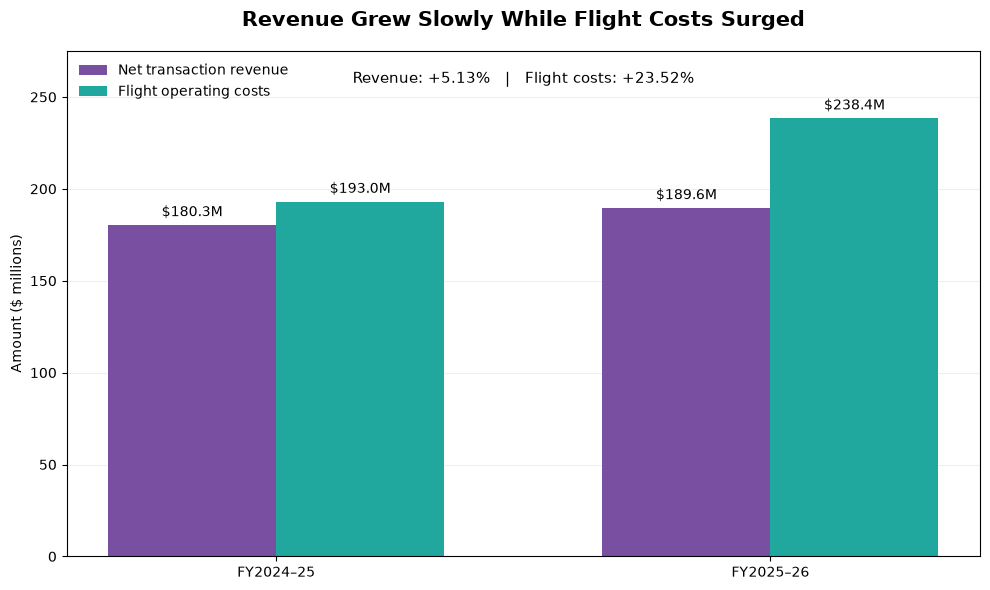

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Purple and teal palette
PURPLE = "#7950A1"
TEAL = "#20A89E"
LIGHT_PURPLE = "#B9A0D0"
DARK_TEAL = "#147D78"

years = ["FY2024–25", "FY2025–26"]
revenue = [180.30, 189.55]
flight_costs = [192.99, 238.38]

x = np.arange(len(years))
width = 0.34

fig, ax = plt.subplots(figsize=(10, 6))

bars_revenue = ax.bar(
    x - width / 2, revenue, width,
    label="Net transaction revenue", color=PURPLE
)
bars_costs = ax.bar(
    x + width / 2, flight_costs, width,
    label="Flight operating costs", color=TEAL
)

ax.bar_label(bars_revenue, fmt="$%.1fM", padding=4)
ax.bar_label(bars_costs, fmt="$%.1fM", padding=4)

ax.set_title(
    "Revenue Grew Slowly While Flight Costs Surged",
    fontsize=15, pad=18, fontweight="bold"
)
ax.set_ylabel("Amount ($ millions)")
ax.set_xticks(x)
ax.set_xticklabels(years)
ax.set_ylim(0, 275)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

ax.text(
    0.5, 0.96,
    "Revenue: +5.13%   |   Flight costs: +23.52%",
    transform=ax.transAxes,
    ha="center", va="top", fontsize=11
)

plt.tight_layout()
plt.show()



### Which cost categories contributed most to the increase

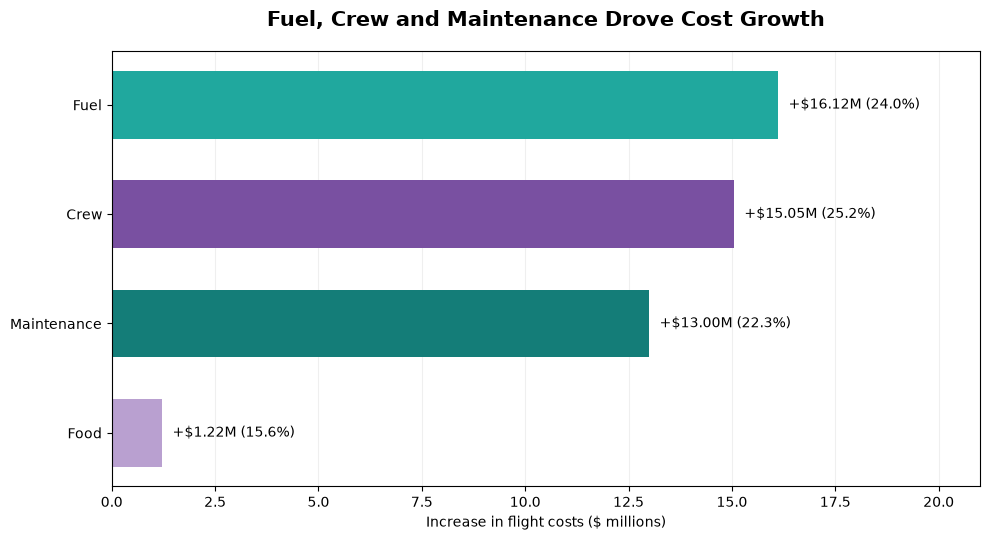

In [ ]:

categories = ["Fuel", "Crew", "Maintenance", "Food"]
increases = [16.12, 15.05, 13.00, 1.22]
growth_rates = [24.04, 25.20, 22.27, 15.56]

# Teal and purple shades
category_colors = [TEAL, PURPLE, DARK_TEAL, LIGHT_PURPLE]

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.barh(
    categories, increases, color=category_colors, height=0.62
)
ax.invert_yaxis()

for bar, amount, growth in zip(bars, increases, growth_rates):
    ax.text(
        bar.get_width() + 0.25,
        bar.get_y() + bar.get_height() / 2,
        f"+${amount:.2f}M ({growth:.1f}%)",
        va="center", fontsize=10
    )

ax.set_title(
    "Fuel, Crew and Maintenance Drove Cost Growth",
    fontsize=15, pad=18, fontweight="bold"
)
ax.set_xlabel("Increase in flight costs ($ millions)")
ax.set_xlim(0, 21)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



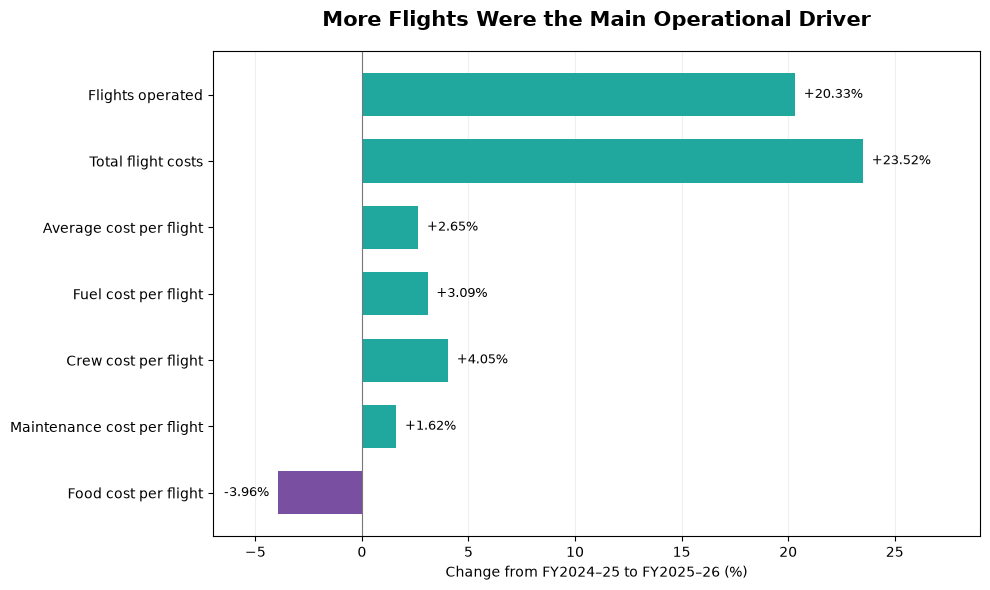

In [ ]:

metrics = [
    "Flights operated",
    "Total flight costs",
    "Average cost per flight",
    "Fuel cost per flight",
    "Crew cost per flight",
    "Maintenance cost per flight",
    "Food cost per flight"
]

changes = [20.33, 23.52, 2.65, 3.09, 4.05, 1.62, -3.96]

fig, ax = plt.subplots(figsize=(10, 6))

bar_colors = [
    TEAL if value >= 0 else PURPLE
    for value in changes
]

bars = ax.barh(metrics, changes, color=bar_colors, height=0.65)
ax.invert_yaxis()
ax.axvline(0, color="#777777", linewidth=0.8)

for bar, change in zip(bars, changes):
    offset = 0.4 if change >= 0 else -0.4
    ax.text(
        change + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{change:+.2f}%",
        va="center",
        ha="left" if change >= 0 else "right",
        fontsize=9
    )

ax.set_title(
    "More Flights Were the Main Operational Driver",
    fontsize=15, pad=18, fontweight="bold"
)
ax.set_xlabel("Change from FY2024–25 to FY2025–26 (%)")
ax.set_xlim(-7, 29)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


## Findings:
#### Revenue grew slower than flight operating costs
Net transaction revenue increased from $180.30 million to $189.55 million (+5.13%), while flight operating costs rose from $192.99 million to $238.38 million (+23.52%), an increase of $45.39 million. This suggests that revenue growth was insufficient to keep up with the rising operating costs.
#### The increase was driven mainly by more flights, and compounded by higher costs per flight
NorthByte operated 15, 729 flights in FY2025-26, up 20.33% from 13,072 flights in FY2024-25. The average cost per flight also increased by 2.65% from $14,763 to $15,155.
#### Fuel, crew, and maintenance accounted for most of the cost increase.
Fuel costs rose by $16.12 million (+24.04%), crew costs by $15.05 million (+25.20%), and maintenance costs by $13.00 million (+22.27%). Per-flight, fuel costs increased by 3.09% and crew costs by 4.05%, which is consistence with the case background's discussion of higher fuel costs and the pilot agreement. Food costs per flight decreased by 3.96%, partially offsetting these increases.
#### The monthly comparison first turned negative in March 2025
Revenue exceeded flight operating costs from September 2024 to February 2025, but begiining in March 2025, costs exceeded revenue and remained higher throughout the months investigated. This suggests that the deterioration began during the second half of FY2024-25
### Overall:
NorthByte's financial pressure appears to come from a combination of increased flights and rising unit costs, while revenue growth lagged behind the cost growth. Improving the revenue per flight and controlling the fuel, crew, and maintance costs are areas for potential further examination.

In [ ]:
gates = gates_file.copy()
# Convert annual gate costs from strings to numeric values
gates["Annual_Gate_Cost"] = pd.to_numeric(
    gates["Annual_Gate_Cost"]
        .astype("string")
        .str.replace(",", "", regex=False)
        .str.strip(),
    errors="coerce"
)

# Check the conversion
print(gates["Annual_Gate_Cost"].dtype)
print("Missing costs:", gates["Annual_Gate_Cost"].isna().sum())

Int64
Missing costs: 0


In [ ]:


gates_unique = gates.drop_duplicates(
    subset=["City", "Gate_Number", "Year", "Annual_Gate_Cost"]
).copy()

gate_year_summary = (
    gates_unique.groupby("Year")
    .agg(
        Unique_Gates=("Gate_Number", "size"),
        Total_Annual_Lease_Cost=("Annual_Gate_Cost", "sum"),
        Average_Cost_Per_Gate=("Annual_Gate_Cost", "mean")
    )
    .reset_index()
)

gate_year_summary

,Year,Unique_Gates,Total_Annual_Lease_Cost,Average_Cost_Per_Gate
0,2024-2025,34,9664400,284247.058824
1,2025-2026,34,9877700,290520.588235


In [ ]:
gate_comparison = gates_unique.pivot_table(
    index=["City", "Gate_Number"],
    columns="Year",
    values="Annual_Gate_Cost",
    aggfunc="first"
).reset_index()

gate_comparison.columns.name = None

gate_comparison = gate_comparison.rename(columns={
    "2024-2025": "Cost_2024_25",
    "2025-2026": "Cost_2025_26"
})

gate_comparison = gate_comparison.dropna(
    subset=["Cost_2024_25", "Cost_2025_26"]
).copy()

gate_comparison["Dollar_Change"] = (
    gate_comparison["Cost_2025_26"]
    - gate_comparison["Cost_2024_25"]
)

gate_comparison["Percent_Change"] = (
    gate_comparison["Dollar_Change"]
    / gate_comparison["Cost_2024_25"] * 100
)

gate_comparison.sort_values(
    "Dollar_Change", ascending=False
).head(10)

,City,Gate_Number,Cost_2024_25,Cost_2025_26,Dollar_Change,Percent_Change
23,Toronto,C2,476400,488800,12400,2.602855
22,Toronto,C1,487700,500000,12300,2.522042
26,Vancouver,A1,466300,477600,11300,2.423333
24,Toronto,C3,455100,466300,11200,2.460998
28,Vancouver,A3,443900,455100,11200,2.523091
25,Toronto,C4,432700,443900,11200,2.588398
27,Vancouver,A2,455100,466300,11200,2.460998
29,Vancouver,A4,417000,427100,10100,2.422062
12,Montreal,D1,394600,404600,10000,2.534212
1,Calgary,B1,373200,382200,9000,2.411576


In [ ]:
gate_comparison["Percent_Change"].describe()

print("Gates with increased costs:",
      (gate_comparison["Dollar_Change"] > 0).sum())

print("Gates with unchanged costs:",
      (gate_comparison["Dollar_Change"] == 0).sum())

print("Gates with decreased costs:",
      (gate_comparison["Dollar_Change"] < 0).sum())

Gates with increased costs: 34
Gates with unchanged costs: 0
Gates with decreased costs: 0


In [ ]:
cost_2024_25 = gate_year_summary.loc[
    gate_year_summary["Year"] == "2024-2025",
    "Total_Annual_Lease_Cost"
].iloc[0]

cost_2025_26 = gate_year_summary.loc[
    gate_year_summary["Year"] == "2025-2026",
    "Total_Annual_Lease_Cost"
].iloc[0]

absolute_change = cost_2025_26 - cost_2024_25
growth_rate = absolute_change / cost_2024_25

forecast_2026_27 = cost_2025_26 * (1 + growth_rate)

print(f"Annual increase: ${absolute_change:,.0f}")
print(f"Historical growth rate: {growth_rate:.2%}")
print(f"FY2026-27 forecast: ${forecast_2026_27:,.0f}")

Annual increase: $213,300
Historical growth rate: 2.21%
FY2026-27 forecast: $10,095,708


### Findings: Gate Lease Costs and Forecast

#### Historical cost changes:
NorthByte's Airlines' total annual gate lease costs increased from $9,664,400 in 2024–25 to $9,877,700 in 2025–26, an increase of $213,300 (2.21%). The number of gates was constant at 34, while the average annual lease cost per gate went from $284,247 to $290,521.

#### Individual gate changes
All 34 gates experienced an increase in annual lease costs. Within the 10 gates with the largest dollar increases, percentage increases ranged from about 2.41% to 2.60%. This suggests that the overall increase was not driven by an extreme outlier.

#### FY2026-27 forecast
Applying the historical 2.21% increase to the 2025-26 total produces a projected annual gate lease cost of approximately $10.10 million for 2026-27, an increase of about $218,008 from the previous year.

In [ ]:
print(
    "Minimum gate-level increase:",
    f"{gate_comparison['Percent_Change'].min():.2f}%"
)

print(
    "Median gate-level increase:",
    f"{gate_comparison['Percent_Change'].median():.2f}%"
)

print(
    "Maximum gate-level increase:",
    f"{gate_comparison['Percent_Change'].max():.2f}%"
)

Minimum gate-level increase: 1.33%
Median gate-level increase: 2.08%
Maximum gate-level increase: 2.60%
